In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

In [2]:
(X_train,y_train),(X_test,y_test) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


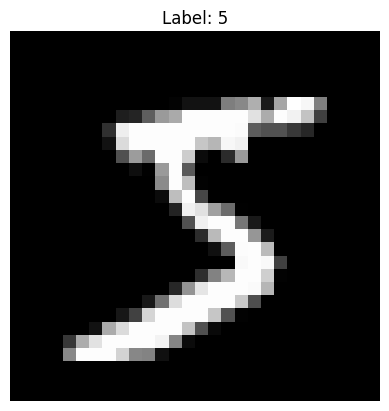

In [3]:
image_index = 0
plt.imshow(X_train[image_index],cmap='gray')
plt.title(f"Label: {y_train[image_index]}")
plt.axis("off")  # Hide coordinate axes
plt.show()

In [4]:
print("training images:{}".format(X_train.shape))
print('training labels:{}'.format(y_train.shape))
print('test images:{}'.format(X_test.shape))
print('test labels:{}'.format(X_test.shape))

training images:(60000, 28, 28)
training labels:(60000,)
test images:(10000, 28, 28)
test labels:(10000, 28, 28)


In [5]:
def create_task(X,y, classes):
    mask = np.isin(y,classes)

    X_task = X[mask]
    y_task = y[mask]

    return X_task, y_task

In [6]:
# task A
X_train_A, y_train_A = create_task(
    X_train,
    y_train,
    [0,1,2,3,4]
)
X_test_A, y_test_A = create_task(
    X_test,
    y_test,
    [0,1,2,3,4]
)

# task B
X_train_B, y_train_B = create_task(
    X_train,
    y_train,
    [5,6,7,8,9]
)
X_test_B, y_test_B = create_task(
    X_test,
    y_test,
    [5,6,7,8,9]
)



In [7]:
#normalizing the images

X_train_A = X_train_A.astype("float32") /255
X_test_A = X_test_A.astype("float32") /255
X_train_B = X_train_B.astype("float32") /255
X_test_B = X_test_B.astype("float32") /255


In [8]:
model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape = (28,28)),
    tf.keras.layers.Dense(128, activation = "relu"),
    tf.keras.layers.Dense(10, activation = "softmax")
])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [9]:
model.compile(
    optimizer = "adam",
    loss = "sparse_categorical_crossentropy",
    metrics = ["accuracy"]
)

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [11]:
history_A = model.fit(
    X_train_A,
    y_train_A,
    epochs = 5,
    batch_size = 128,
    validation_data = (X_test_A,y_test_A)
)

Epoch 1/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9437 - loss: 0.2115 - val_accuracy: 0.9796 - val_loss: 0.0728
Epoch 2/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9780 - loss: 0.0738 - val_accuracy: 0.9848 - val_loss: 0.0507
Epoch 3/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9856 - loss: 0.0505 - val_accuracy: 0.9864 - val_loss: 0.0397
Epoch 4/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9879 - loss: 0.0400 - val_accuracy: 0.9905 - val_loss: 0.0321
Epoch 5/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9913 - loss: 0.0291 - val_accuracy: 0.9903 - val_loss: 0.0299


In [12]:
# lets measure our baseline, lets get our accuracy of A and loss before training task two
loss_A_before , accuracy_A_before = model.evaluate(
    X_test_A,
    y_test_A,
    verbose = 0
)

print("Task A accuracy before Task B:{}".format(accuracy_A_before))

Task A accuracy before Task B:0.9902704954147339


In [13]:
accuracy_of_taskA_beforeB = 0.9904650449752808

In [14]:
#lets evaluate the model on task b and so we could compare after training task B
loss_B_before, accuracy_B_before = model.evaluate(
    X_test_B,
    y_test_B,
    verbose= 0
)
print("Task B accuracy before Training :{}".format(accuracy_B_before))


Task B accuracy before Training :0.0


In [15]:
history_B = model.fit(
    X_train_B,
    y_train_B,
    epochs = 4,
    batch_size = 128,
    validation_data= (X_test_B,y_test_B)
)

Epoch 1/4
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9030 - loss: 0.4185 - val_accuracy: 0.9621 - val_loss: 0.1250
Epoch 2/4
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9709 - loss: 0.0975 - val_accuracy: 0.9706 - val_loss: 0.0923
Epoch 3/4
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9783 - loss: 0.0734 - val_accuracy: 0.9749 - val_loss: 0.0737
Epoch 4/4
230/230 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9823 - loss: 0.0602 - val_accuracy: 0.9761 - val_loss: 0.0694


In [16]:
loss_A_after , accuracy_A_after = model.evaluate(
    X_test_A,
    y_test_A,
    verbose = 0
)

print("Task A accuracy after Task B:{}".format(accuracy_A_after))

Task A accuracy after Task B:0.0


In [17]:
loss_B_after , accuracy_B_after = model.evaluate(
    X_test_B,
    y_test_B,
    verbose = 0
)

print("Task B accuracy after:{}".format(accuracy_B_after))

Task B accuracy after:0.9761366248130798


In [18]:
## with this we notice a 100% forgetting of task a

In [19]:
accuracy_A_before

0.9902704954147339

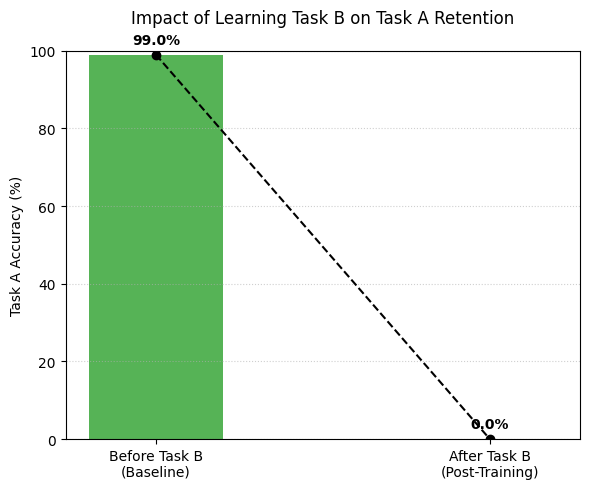

In [34]:

# Convert to percentages for better readability
accuracies = [accuracy_A_before * 100, accuracy_A_after * 100]
labels = ['Before Task B\n(Baseline)', 'After Task B\n(Post-Training)']

plt.figure(figsize=(6, 5))

# Plot the bars
bars = plt.bar(labels, accuracies, color=['#2ca02c', '#d62728'], width=0.4, alpha=0.8)

# Add a trendline to clearly connect the transition
plt.plot(labels, accuracies, color='black', linestyle='--', marker='o', linewidth=1.5)

# Style adjustments
plt.ylabel('Task A Accuracy (%)')
plt.title('Impact of Learning Task B on Task A Retention',pad=20)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Add value labels on top of the bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


In [21]:
# implementing experience replay

memory_size = 1000

X_memory = X_train_A[:memory_size]
y_memory = y_train_A[:memory_size]

X_memory.shape, y_memory.shape

((1000, 28, 28), (1000,))

In [22]:
experience_replay_model = tf.keras.Sequential([
    tf.keras.layers.Flatten(input_shape = (28,28)),
    tf.keras.layers.Dense(128, activation = "relu"),
    tf.keras.layers.Dense(10, activation = "softmax")
])
experience_replay_model.compile(
    optimizer="adam",
    loss = "sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [23]:
experience_replay_model.fit(
    X_train_A,
    y_train_A,
    epochs = 5,
    batch_size = 128,
    verbose=1
)

Epoch 1/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9486 - loss: 0.1954
Epoch 2/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9780 - loss: 0.0746
Epoch 3/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9851 - loss: 0.0527
Epoch 4/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9881 - loss: 0.0410
Epoch 5/5
240/240 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9910 - loss: 0.0307


In [24]:
replay_A_before = experience_replay_model.evaluate(
    X_test_A,
    y_test_A,
    verbose= 0
)[1]
print("Task A accuracy before Task B:",
      replay_A_before)

Task A accuracy before Task B: 0.9900758862495422


In [25]:
X_replay = np.concatenate(
    [X_train_B,X_memory],
    axis=0
)

y_replay = np.concatenate(
    [y_train_B,y_memory],
    axis=0
)

In [26]:
X_replay.shape, y_replay.shape

((30404, 28, 28), (30404,))

In [27]:
experience_replay_model.fit(
    X_replay,
    y_replay,
    epochs = 5,
    batch_size=128,
    shuffle = True,
    verbose = 1
)

Epoch 1/5
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8971 - loss: 0.4656
Epoch 2/5
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9605 - loss: 0.1338
Epoch 3/5
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9713 - loss: 0.1018
Epoch 4/5
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9760 - loss: 0.0830
Epoch 5/5
238/238 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9808 - loss: 0.0694


In [28]:
replay_A_after = experience_replay_model.evaluate(
    X_test_A,
    y_test_A,
    verbose= 0
)[1]
print("Task A accuracy after experience replay with Task B:",
      replay_A_after)

Task A accuracy after experience replay with Task B: 0.7985989451408386


In [29]:
replay_B_after = experience_replay_model.evaluate(
    X_test_B,
    y_test_B,
    verbose=0
)[1]

print("Task B accuracy after training:",
      replay_B_after)

Task B accuracy after training: 0.9769594669342041


In [30]:
replay_forgetting = (
    replay_A_before - replay_A_after
)

print(
    f"Forgetting with replay: "
    f"{replay_forgetting * 100:.2f} percentage points"
)

Forgetting with replay: 19.15 percentage points


In [31]:
## comparing the two experiments
print(
    f"Without replay: "
    f"{accuracy_A_before:.4f} → {accuracy_A_after:.4f}"
)

print(
    f"With replay:    "
    f"{replay_A_before:.4f} → {replay_A_after:.4f}"
)

Without replay: 0.9903 → 0.0000
With replay:    0.9901 → 0.7986


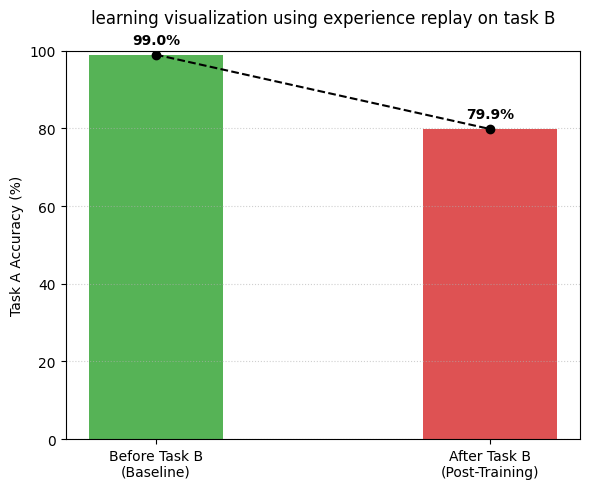

In [35]:

# Convert to percentages for better readability
replay_accuracies = [replay_A_before * 100, replay_A_after * 100]
replay_labels = ['Before Task B\n(Baseline)', 'After Task B\n(Post-Training)']

plt.figure(figsize=(6, 5))

# Plot the bars
bars = plt.bar(replay_labels, replay_accuracies, color=['#2ca02c', '#d62728'], width=0.4, alpha=0.8)

# Add a trendline to clearly connect the transition
plt.plot(replay_labels, replay_accuracies, color='black', linestyle='--', marker='o', linewidth=1.5)

# Style adjustments
plt.ylabel('Task A Accuracy (%)')
plt.title('learning visualization using experience replay on task B',pad=20)
plt.ylim(0, 100)
plt.grid(axis='y', linestyle=':', alpha=0.6)

# Add value labels on top of the bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 2,
             f'{height:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()
